In [1]:
# Install all packages required for this talktorial
%pip install requests pandas rdkit

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
from pathlib import Path

import requests

import pandas as pd

# PandasTool is not required


In [3]:
# Resolve the repository root from the kernel working directory.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / ".git").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the repository root from the current directory.")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data"


In [4]:
# --- ChEMBL API helpers ---
BASE_URL = "https://www.ebi.ac.uk/chembl/api/data"

# Fetch all pages from a ChEMBL REST API endpoint.
def get_json(endpoint, params=None):
    """Return all records for an endpoint, following ChEMBL's pagination.

    Args:
        endpoint: API resource path, such as ``target`` or ``activity``.
        params: Optional query parameters; ``limit`` and ``offset`` are managed here.
    """
    params = params.copy() if params else {}
    params.setdefault("limit", 1000)

    records = []
    offset = 0

    while True:
        params["offset"] = offset

        response = requests.get(
            f"{BASE_URL}/{endpoint}.json",
            params=params,
            headers={"Accept": "application/json"},
            timeout=30,
        )

        response.raise_for_status()
        data = response.json()
        collection_name = next(
            key
            for key in data.keys()
            if isinstance(data[key], list)
        )

        batch = data[collection_name]

        if not batch:
            break

        records.extend(batch)

        if len(batch) < params["limit"]:
            break

        offset += params["limit"]

    return records


In [5]:
# Find ChEMBL targets by UniProt accession and keep useful target metadata.
def get_targets(uniprot_id):
    """Return matching target records for a UniProt accession as a DataFrame.

    Args:
        uniprot_id: UniProt accession used to search ChEMBL target components.
    """
    targets = get_json(
        "target",
        {
            "target_components__accession": uniprot_id
        }
    )

    targets = pd.DataFrame(targets)

    # Add columns to the DataFrame if it is not empty
    if not targets.empty:
        columns = [
            "target_chembl_id",
            "organism",
            "pref_name",
            "target_type",
        ]

        targets = targets[columns]

    return targets

In [6]:
# Retrieve and select activity records for one ChEMBL target.
def get_activities(
    target_chembl_id,
    activity_type="IC50",
    relation="=",
    assay_type="B",
):
    """Return activity measurements matching the target and assay filters.

    Args:
        target_chembl_id: ChEMBL identifier of the target to query.
        activity_type: Measurement type, defaulting to IC50.
        relation: Measurement relation, defaulting to exact values only.
        assay_type: ChEMBL assay category, defaulting to binding assays.
    """

    activities = get_json(
        "activity",
        {
            "target_chembl_id": target_chembl_id,
            "type": activity_type,
            "relation": relation,
            "assay_type": assay_type,
        },
    )

    activities = pd.DataFrame(activities)

    if not activities.empty:
        columns = [
            "activity_id",
            "assay_chembl_id",
            "assay_description",
            "assay_type",
            "molecule_chembl_id",
            "type",
            "standard_units",
            "relation",
            "standard_value",
            "target_chembl_id",
            "target_organism",
        ]

        available = [
            c for c in columns
            if c in activities.columns
        ]

        activities = activities[available]

    return activities


In [7]:
# Retrieve molecular structures in batches to keep API requests manageable.
def get_compounds(molecule_chembl_ids, batch_size=100):
    """Return molecule IDs and structure records for the requested compounds.

    Duplicate IDs are removed before requesting batches from ChEMBL.

    Args:
        molecule_chembl_ids: ChEMBL molecule IDs associated with the activities.
        batch_size: Maximum number of IDs included in each API request.
    """

    molecule_chembl_ids = list(set(molecule_chembl_ids))
    compounds = []

    for start in range(0, len(molecule_chembl_ids), batch_size):
        batch = molecule_chembl_ids[start:start + batch_size]
        ids = ";".join(batch)

        data = get_json(
            f"molecule/set/{ids}"
        )
        for molecule in data:
            compounds.append(
                {
                    "molecule_chembl_id": molecule["molecule_chembl_id"],
                    "molecule_structures": molecule["molecule_structures"],
                }
            )

        print(
            f"Retrieved {len(compounds)} compounds...",
            end="\r"
        )

    return pd.DataFrame(compounds)

In [8]:
# --- Select DRD2 and retrieve its bioactivity measurements ---
uniprot_id = "P14416"

In [9]:
# Get target information from ChEMBL but restrict it to specified values only
targets = get_targets(uniprot_id)

print(f"The type of targets is {type(targets)}")

The type of targets is <class 'pandas.DataFrame'>


In [10]:
# Let's have a look at the target information we retrieved from ChEMBL
targets.head()

,target_chembl_id,organism,pref_name,target_type
0,CHEMBL217,Homo sapiens,D(2) dopamine receptor,SINGLE PROTEIN
1,CHEMBL2095169,Homo sapiens,Dopamine receptors; D2 & D3,SELECTIVITY GROUP
2,CHEMBL2095396,Homo sapiens,Dopamine receptors; D2 & D4,SELECTIVITY GROUP
3,CHEMBL2096905,Homo sapiens,Dopamine receptor,PROTEIN FAMILY
4,CHEMBL2111460,Homo sapiens,Dopamine D2 receptor and serotonin 1a receptor,SELECTIVITY GROUP


In [11]:
target = targets.iloc[0]
target

target_chembl_id                 CHEMBL217
organism                      Homo sapiens
pref_name           D(2) dopamine receptor
target_type                 SINGLE PROTEIN
Name: 0, dtype: str

In [12]:
chembl_id = target.target_chembl_id
print(f"The target ChEMBL ID is {chembl_id}")

The target ChEMBL ID is CHEMBL217


In [13]:
bioactivities = get_activities(chembl_id)

print(
    f"Length and type of bioactivities object: "
    f"{len(bioactivities)}, {type(bioactivities)}"
)


Length and type of bioactivities object: 514, <class 'pandas.DataFrame'>


In [14]:
# Check the number of unique molecules
print(bioactivities["molecule_chembl_id"].nunique())

435


In [15]:
bioactivities.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type,standard_units,relation,standard_value,target_chembl_id,target_organism
0,32111,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL303519,IC50,nM,=,9800.0,CHEMBL217,Homo sapiens
1,33282,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL292943,IC50,nM,=,50.0,CHEMBL217,Homo sapiens
2,38258,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL61682,IC50,nM,=,25.0,CHEMBL217,Homo sapiens
3,39387,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64487,IC50,nM,=,360.0,CHEMBL217,Homo sapiens
4,39391,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64597,IC50,nM,=,300.0,CHEMBL217,Homo sapiens


In [16]:
bioactivities.dtypes

activity_id           int64
assay_chembl_id         str
assay_description       str
assay_type              str
molecule_chembl_id      str
type                    str
standard_units          str
relation                str
standard_value          str
target_chembl_id        str
target_organism         str
dtype: object

In [17]:
bioactivities = bioactivities.astype({"standard_value": "float64"})
bioactivities.dtypes

activity_id             int64
assay_chembl_id           str
assay_description         str
assay_type                str
molecule_chembl_id        str
type                      str
standard_units            str
relation                  str
standard_value        float64
target_chembl_id          str
target_organism           str
dtype: object

In [18]:
# --- Clean and standardize bioactivity measurements ---
# Remove incomplete records before applying unit and duplicate filters.
bioactivities.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {bioactivities.shape}")

DataFrame shape: (514, 11)


In [19]:
print(f"Units in downloaded data: {bioactivities['standard_units'].unique()}")
print(
    f"Number of non-nM entries:\
    {bioactivities[bioactivities['standard_units'] != 'nM'].shape[0]}"
)

Units in downloaded data: <StringArray>
['nM']
Length: 1, dtype: str
Number of non-nM entries:    0


In [20]:
bioactivities = bioactivities[bioactivities["standard_units"] == "nM"]
print(f"Units after filtering: {bioactivities['standard_units'].unique()}")

Units after filtering: <StringArray>
['nM']
Length: 1, dtype: str


In [21]:
print(f"DataFrame shape: {bioactivities.shape}")

DataFrame shape: (514, 11)


In [22]:
bioactivities.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)
print(f"DataFrame shape: {bioactivities.shape}")

DataFrame shape: (435, 11)


In [23]:
bioactivities.reset_index(drop=True, inplace=True)
bioactivities.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type,standard_units,relation,standard_value,target_chembl_id,target_organism
0,32111,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL303519,IC50,nM,=,9800.0,CHEMBL217,Homo sapiens
1,33282,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL292943,IC50,nM,=,50.0,CHEMBL217,Homo sapiens
2,38258,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL61682,IC50,nM,=,25.0,CHEMBL217,Homo sapiens
3,39387,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64487,IC50,nM,=,360.0,CHEMBL217,Homo sapiens
4,39391,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64597,IC50,nM,=,300.0,CHEMBL217,Homo sapiens


In [24]:
bioactivities.rename(
    columns={"standard_value": "IC50", "standard_units": "units"}, inplace=True
)
bioactivities.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type,units,relation,IC50,target_chembl_id,target_organism
0,32111,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL303519,IC50,nM,=,9800.0,CHEMBL217,Homo sapiens
1,33282,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL292943,IC50,nM,=,50.0,CHEMBL217,Homo sapiens
2,38258,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL61682,IC50,nM,=,25.0,CHEMBL217,Homo sapiens
3,39387,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64487,IC50,nM,=,360.0,CHEMBL217,Homo sapiens
4,39391,CHEMBL671073,Binding affinity to cloned human Dopamine rece...,B,CHEMBL64597,IC50,nM,=,300.0,CHEMBL217,Homo sapiens


In [25]:
print(f"DataFrame shape: {bioactivities.shape}")

DataFrame shape: (435, 11)


In [26]:
print(len(bioactivities))
print(bioactivities["molecule_chembl_id"].nunique())

435
435


In [27]:
# --- Retrieve molecular structures for the curated activity records ---
compounds = get_compounds(bioactivities["molecule_chembl_id"].unique())

In [28]:
compounds.head()

,molecule_chembl_id,molecule_structures
0,CHEMBL5558995,{'canonical_smiles': 'COc1cc2c(cc1OC)Oc1c(O)cc...
1,CHEMBL235212,{'canonical_smiles': 'COc1ccc(C[C@H]2c3cc(O)c(...
2,CHEMBL6007113,{'canonical_smiles': 'O=C1CCc2ccc(CCN3CCN(c4cc...
3,CHEMBL5960228,{'canonical_smiles': 'CC(=O)N1CC(CCN2CCN(c3ccc...
4,CHEMBL259199,{'canonical_smiles': 'CCOc1ccccc1N1CCN(CCCC(=O...


In [29]:
compounds.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {compounds.shape}")

DataFrame shape: (435, 2)


In [30]:
print(f"Bioactivities filtered: {bioactivities.shape[0]}")
bioactivities.columns

Bioactivities filtered: 435


Index(['activity_id', 'assay_chembl_id', 'assay_description', 'assay_type',
       'molecule_chembl_id', 'type', 'units', 'relation', 'IC50',
       'target_chembl_id', 'target_organism'],
      dtype='str')

In [31]:
print(f"Compounds filtered: {compounds.shape[0]}")
compounds.columns

Compounds filtered: 435


Index(['molecule_chembl_id', 'molecule_structures'], dtype='str')

In [32]:
# --- Combine activity measurements and compound structures ---
# Join on the ChEMBL molecule ID so each activity has its compound structure.
output_df = pd.merge(
    bioactivities[["molecule_chembl_id", "IC50", "units"]],
    compounds,
    on="molecule_chembl_id",
)

# Reset row indices
output_df.reset_index(drop=True, inplace=True)

print(f"Dataset with {output_df.shape[0]} entries.")

Dataset with 435 entries.


In [33]:
output_df.dtypes

molecule_chembl_id         str
IC50                   float64
units                      str
molecule_structures     object
dtype: object

In [34]:
output_df.head(10)

,molecule_chembl_id,IC50,units,molecule_structures
0,CHEMBL303519,9800.0,nM,{'canonical_smiles': 'c1cnc(N2CCN(Cc3cccc4c3Cc...
1,CHEMBL292943,50.0,nM,{'canonical_smiles': 'COc1ccc(-c2cccc(CN3CCN(c...
2,CHEMBL61682,25.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cncc(CN3CCN(c4...
3,CHEMBL64487,360.0,nM,{'canonical_smiles': 'COc1ccccc1-c1cccc(CN2CCN...
4,CHEMBL64597,300.0,nM,{'canonical_smiles': 'c1cnc(N2CCN(Cc3cccc(-c4c...
5,CHEMBL291824,70.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cncc(CN3CCN(c4...
6,CHEMBL59942,49.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cccc(CN3CCN(c4...
7,CHEMBL61657,60.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cncc(CN3CCN(c4...
8,CHEMBL302183,120.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cncc(CN3CCN(c4...
9,CHEMBL304692,2300.0,nM,{'canonical_smiles': 'c1cnc(N2CCN(Cc3cccc4c3-c...


In [35]:
# Convert IC50 values in nanomolar units to the logarithmic pIC50 scale.
def convert_ic50_to_pic50(IC50_value):
    """Convert a positive IC50 value in nM to pIC50 (9 - log10(IC50)).

    Args:
        IC50_value: IC50 measurement in nanomolar units.
    """
    pIC50_value = 9 - math.log10(IC50_value)
    return pIC50_value

In [36]:
# --- Calculate pIC50 from IC50 measurements ---
# Apply the nM-to-pIC50 conversion to each joined activity record.
output_df["pIC50"] = output_df.apply(lambda x: convert_ic50_to_pic50(x.IC50), axis=1)

In [37]:
output_df.head()

,molecule_chembl_id,IC50,units,molecule_structures,pIC50
0,CHEMBL303519,9800.0,nM,{'canonical_smiles': 'c1cnc(N2CCN(Cc3cccc4c3Cc...,5.008774
1,CHEMBL292943,50.0,nM,{'canonical_smiles': 'COc1ccc(-c2cccc(CN3CCN(c...,7.301030
2,CHEMBL61682,25.0,nM,{'canonical_smiles': 'Fc1ccc(-c2cncc(CN3CCN(c4...,7.602060
3,CHEMBL64487,360.0,nM,{'canonical_smiles': 'COc1ccccc1-c1cccc(CN2CCN...,6.443697
4,CHEMBL64597,300.0,nM,{'canonical_smiles': 'c1cnc(N2CCN(Cc3cccc(-c4c...,6.522879


array([[<Axes: title={'center': 'pIC50'}>]], dtype=object)

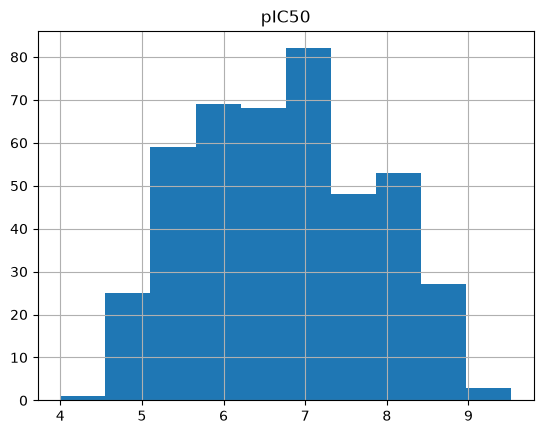

In [38]:
output_df.hist(column="pIC50")

In [39]:
# --- Extract and validate molecular structures ---
from rdkit import Chem

# Extract canonical SMILES from ChEMBL's nested structure records.
output_df["smiles"] = output_df["molecule_structures"].apply(
    lambda structure: structure.get("canonical_smiles")
    if isinstance(structure, dict)
    else None
)

# Parse SMILES with RDKit; invalid or missing strings produce a missing molecule.
output_df["ROMol"] = output_df["smiles"].apply(
    lambda smiles: Chem.MolFromSmiles(smiles) if pd.notna(smiles) else None
)

In [40]:
# Sort molecules by pIC50
output_df.sort_values(by="pIC50", ascending=False, inplace=True)

# Reset index
output_df.reset_index(drop=True, inplace=True)

In [41]:
output_df.drop("molecule_structures", axis=1).head(3)

,molecule_chembl_id,IC50,units,pIC50,smiles,ROMol
0,CHEMBL567,0.30,nM,9.522879,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1,<rdkit.Chem.rdchem.Mol object at 0x000001B76D6...
1,CHEMBL6004129,0.98,nM,9.008774,COc1ccccc1N1CCN(CCCCOc2ccc3c(c2)NC(=O)CO3)CC1,<rdkit.Chem.rdchem.Mol object at 0x000001B76D6...
2,CHEMBL5851827,1.06,nM,8.974694,O=C1CCc2cc(CCCCN3CCN(c4cccc5sc(F)cc45)CC3)ccc2N1,<rdkit.Chem.rdchem.Mol object at 0x000001B76D6...


In [42]:
# Remove temporary RDKit objects before exporting the table.
output_df = output_df.drop("ROMol", axis=1)
print(f"DataFrame shape: {output_df.shape}")

DataFrame shape: (435, 6)


In [43]:
# --- Prepare the final CSV columns ---
DATA.mkdir(parents=True, exist_ok=True)
output_df = output_df[["molecule_chembl_id", "pIC50", "smiles"]].copy()
output_df = output_df.rename(columns={"molecule_chembl_id": "CHEMBLid"})

output_df.head(5)

,CHEMBLid,pIC50,smiles
0,CHEMBL567,9.522879,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1
1,CHEMBL6004129,9.008774,COc1ccccc1N1CCN(CCCCOc2ccc3c(c2)NC(=O)CO3)CC1
2,CHEMBL5851827,8.974694,O=C1CCc2cc(CCCCN3CCN(c4cccc5sc(F)cc45)CC3)ccc2N1
3,CHEMBL8514,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@H]3c4ccccc4CCc4cccc(c4...
4,CHEMBL3885419,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@@H]3c4ccccc4CCc4cccc(c...


In [44]:
# --- Export the curated DRD2 compound table ---
DATA.mkdir(parents=True, exist_ok=True)
output_df.to_csv(DATA / "drd2_curated_compounds.csv", index=False)
print(f"Saved {len(output_df)} compounds to {DATA / 'drd2_curated_compounds.csv'}")

Saved 435 compounds to C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\data\drd2_curated_compounds.csv
